<!-- CURRICULUM_HEADER_START -->
<div class="mh"><p class="mh-crumb"><a href="/series/prediction/index.html">Weather, Climate and Prediction</a><span class="sep">·</span>Part 7 · Extremes</p><p class="mh-facts"><span class="lvl lvl-advanced">Advanced</span></p><p class="mh-assumes">Assumes <a href="/blogs/return-periods.html">Return periods</a> and <a href="/blogs/heavy-tails.html">Heavy tails</a>.</p></div>
<!-- CURRICULUM_HEADER_END -->

::: {.callout-note appearance="simple" icon=false}
## TL;DR

The largest value in a year follows its own distribution, not the daily one. Maxima of many independent days settle on one family, the generalised extreme value (GEV) distribution, whatever the days' own distribution. Its shape ξ sets the tail: above zero heavy and unbounded, at zero the Gumbel, below zero a hard upper limit. Fitting it to yearly maxima, or a generalised Pareto to every day above a high threshold, is how a 1-in-100-year level is estimated from a shorter record. On synthetic daily rain with a true 1-in-100-year level of 115.7 mm, GEV fits to 1000 different 30-year records put it between 77 and 207 mm in 9 records of 10, and a quarter of them wrongly found an upper limit. A Gumbel fit was tighter but too low 90% of the time. Never quote a rare level from a few decades without its interval.
:::

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from scipy import optimize, stats

# fallcolor is the site's colour module in tools/, not an installed package.
here = [Path.cwd(), *Path.cwd().parents]
sys.path.insert(0, str(next(p / "tools" for p in here if (p / "tools/fallcolor.py").exists())))
import fallcolor

fallcolor.palette.use("default")
plt.rcParams["figure.dpi"] = 110
C1, C2, C3, C4 = fallcolor.palette.discrete("default")
gev, gpd = stats.genextreme, stats.genpareto  # scipy: genextreme c = -xi, genpareto c = +xi

## Why maxima have their own distribution

Yearly maxima of almost any daily quantity follow one three-parameter family, and its shape parameter decides how fast rare levels climb. That is what makes a 1-in-100-year estimate from 30 years possible at all.

[Return periods](../return-periods.qmd) stopped at the edge of the record, about 1-in-31 for 30 years. Fitting the daily values does not help: with independent days of distribution function $F$, the largest of $n = 365$ has $P(\max \le x) = F(x)^{n}$, which depends only on the far tail of $F$, the part a record samples worst. Extreme value theory replaces $F^n$ with its limit. Fisher and Tippett showed that the limit for a sample's largest value, shifted and rescaled, is restricted to a few forms, and that which one applies depends on how fast the chance of exceeding $x$ falls[^1]. The Fisher–Tippett–Gnedenko theorem gathers them into the GEV:

$$G(z) = \exp\left\{-\left[1 + \xi\,\frac{z-\mu}{\sigma}\right]^{-1/\xi}\right\}, \qquad 1 + \xi\,\frac{z-\mu}{\sigma} > 0$$

where $G(z)$ is the probability that the year's maximum is at most $z$ (mm of rain here), the location $\mu$ (mm) and scale $\sigma > 0$ (mm) place and stretch it, and the dimensionless shape $\xi$ sets the tail[^3]. As $\xi \to 0$ it becomes the Gumbel of Return periods.

| Shape | Name | Upper tail | Parent tail |
|---|---|---|---|
| $\xi > 0$ | Fréchet | Heavy, unbounded | Power law, index $\alpha$: $\xi = 1/\alpha$ |
| $\xi = 0$ | Gumbel | Thin, unbounded | Exponential, normal, gamma |
| $\xi < 0$ | Reversed Weibull | Ends at $\mu - \sigma/\xi$ | Bounded |

$\alpha$ is the tail index of [Heavy tails](../heavy-tails.qmd). The cell tests the table on four synthetic parents.

In [2]:
rng = np.random.default_rng(1)  # 2000 synthetic "years" of 365 independent days from each parent
parents = {"exponential": rng.exponential(1, (2000, 365)), "Pareto, alpha = 4": rng.pareto(4, (2000, 365)) + 1,
           "beta(2, 4)": rng.beta(2, 4, (2000, 365)), "normal": rng.normal(0, 1, (2000, 365))}
for name, days in parents.items():
    c = gev.fit(days.max(axis=1))[0]
    print(f"{name:18s} scipy c = {c:+.3f}  ->  xi = {-c:+.3f}")

exponential        scipy c = -0.018  ->  xi = +0.018
Pareto, alpha = 4  scipy c = -0.256  ->  xi = +0.256
beta(2, 4)         scipy c = +0.258  ->  xi = -0.258
normal             scipy c = +0.082  ->  xi = -0.082


The Pareto with $\alpha = 4$ gives $\hat\xi = 0.256$ against $1/\alpha = 0.25$; the beta(2, 4), whose survival function falls like $(1-x)^4$ at its upper end, gives $-0.258$ against $-1/4$ (my calculation). The normal belongs to the Gumbel but gives $-0.082$, because normal maxima approach their limit extremely slowly[^1], which Papalexiou and Koutsoyiannis argue makes even Gumbel-type rainfall maxima look Fréchet in real records[^2]. The theorem gives the family; the data must give $\xi$.

::: {.callout-important appearance="simple"}
## scipy's sign for the shape

`scipy.stats.genextreme` uses $c = -\xi$, so a heavy tail has a *negative* `c`. `scipy.stats.genpareto` uses $c = +\xi$. Hydrology papers also often reverse the sign[^3].
:::

The shape controls the extrapolation. The return level for a period of $T$ years, in mm, is[^3]

$$z_T = \mu + \frac{\sigma}{\xi}\left\{\left[-\ln\left(1 - 1/T\right)\right]^{-\xi} - 1\right\}$$

xi = +0.2: 1-in-1000 level 14.90
xi = +0.0: 1-in-1000 level 6.91
xi = -0.2: 1-in-1000 level 3.74


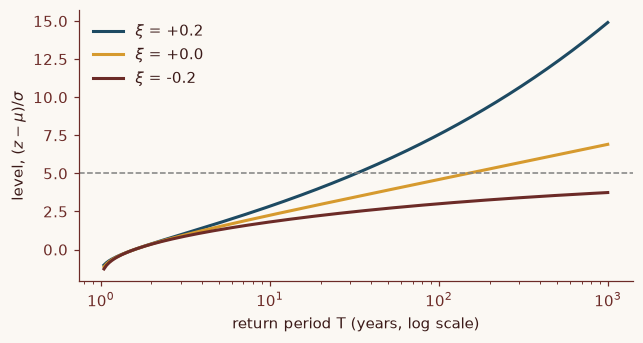

In [3]:
T = np.logspace(0.02, 3, 200)  # return period, years
fig, ax = plt.subplots(figsize=(6.5, 3.2))
for xi, col in [(0.2, C1), (0.0, C2), (-0.2, C3)]:
    ax.semilogx(T, gev.isf(1 / T, -xi), color=col, lw=2, label=rf"$\xi$ = {xi:+.1f}")
    print(f"xi = {xi:+.1f}: 1-in-1000 level {gev.isf(0.001, -xi):.2f}")
ax.axhline(5, color="0.5", ls="--", lw=1)  # upper limit mu - sigma/xi for xi = -0.2
ax.set(xlabel="return period T (years, log scale)", ylabel=r"level, $(z - \mu)/\sigma$"); ax.legend(frameon=False)
plt.show()

**Figure 1 | Return levels for three shapes**, in scale units $(z_T - \mu)/\sigma$. Dashed, the upper limit $\mu - \sigma/\xi = 5$ for $\xi = -0.2$.

The curves agree below 1-in-10, where 30 years can see; at 1-in-1000 a shape of 0.2 instead of 0 doubles the level ($14.90/6.91 = 2.16$).

::: {.callout-note collapse="true"}
## How a limit appears, and why only these shapes

For an exponential parent with mean 1, $F(x) = 1 - e^{-x}$, and the largest of $n$ values satisfies

$$P(\max \le x + \ln n) = \left(1 - \frac{e^{-x}}{n}\right)^{n} \;\to\; \exp\left(-e^{-x}\right) \quad (n \to \infty)$$

the Gumbel: a shift of $\ln n$ is all the rescaling needed. In general, the largest of $2n$ values is the larger of two maxima of $n$, so any limit $G$ must satisfy $G(x)^2 = G(ax + b)$ for some $a > 0$ and $b$: a maximum of blocks has the shape of one block, moved and stretched. Fisher and Tippett solved this equation[^1]; its solutions are the GEV family.
:::

## Yearly maxima or every large event

Fitting each year's largest day uses 30 values from 30 years; fitting every day above a high threshold uses several times as many. The price is choosing the threshold.

From here on the data are **synthetic** daily rain with a known truth, a stand-in for testing methods and not a calibrated climate of any place. 30% of days are wet; a wet day is drizzle (exponential, mean 4 mm) or, one time in five, a storm (generalised Pareto, $\xi = 0.1$, scale 10 mm). The storms' tail is the heaviest part, so the maxima's true shape is $\xi = 0.1$. With independent days, $P(\text{year's max} \le x) = (1 - 0.3\,S(x))^{365}$, where $S(x)$ is the chance a wet day exceeds $x$, so every true return level is exact.

365 independent days is the toy part. Real wet days cluster and a wet season concentrates the storms, so a year holds fewer effectively independent days and, by my reasoning, its maximum sits further from the limit. That is part of why threshold analyses decluster and model the annual cycle[^3].

In [4]:
# Synthetic daily rain (mm): 30% of days wet; a wet day is drizzle (exponential, mean 4 mm)
# or, one time in five, a storm (generalised Pareto, xi = 0.1, scale 10 mm). Days independent.
P_WET, P_STORM, MEAN_DRIZZLE, XI, SIGMA = 0.3, 0.2, 4.0, 0.1, 10.0
wet_sf = lambda x: (1 - P_STORM) * np.exp(-x / MEAN_DRIZZLE) + P_STORM * gpd.sf(x, XI, scale=SIGMA)
# exact truth: P(year's max <= x) = (1 - P_WET * wet_sf(x))**365
true_level = lambda T: optimize.brentq(lambda x: (1 - P_WET * wet_sf(x)) ** 365 - (1 - 1 / T), 1, 2000)

def daily_rain(rng, years):
    n = years * 365
    storm = gpd.rvs(XI, scale=SIGMA, size=n, random_state=rng)
    x = np.where(rng.random(n) < P_STORM, storm, rng.exponential(MEAN_DRIZZLE, n))
    return (x * (rng.random(n) < P_WET)).reshape(years, 365)

TRUE100 = true_level(100)
rain = daily_rain(np.random.default_rng(1), 30)  # one 30-year record
annual_max, wet = rain.max(axis=1), rain[rain > 0]
print(f"true 1-in-100 level {TRUE100:.1f} mm; record's wettest year {annual_max.max():.1f} mm")

true 1-in-100 level 115.7 mm; record's wettest year 131.9 mm


This record's wettest year, 131.9 mm, already exceeds the true 1-in-100-year level of 115.7 mm.

Above a high threshold $u$ (mm), the excess $y = X - u$ (mm) of a day's rain $X$ approximately follows the **generalised Pareto distribution** (GPD)[^4]:

$$P(X - u > y \mid X > u) = \left(1 + \xi\,\frac{y}{\sigma_u}\right)^{-1/\xi}, \qquad y \ge 0$$

with the same $\xi$ as the maxima's GEV and scale $\sigma_u = \sigma + \xi(u - \mu)$ (mm). This is the same limit seen from the threshold side, the Pickands–Balkema–de Haan theorem; Katz and colleagues present the GPD as the approximation for excesses over a high threshold and derive the link to the GEV[^3]. With $\lambda$ exceedances per year, setting the expected exceedances of $z_T$ per year to $1/T$ gives

$$z_T = u + \frac{\sigma_u}{\xi}\left[(\lambda T)^{\xi} - 1\right]$$

To choose $u$, plot the **mean excess** $e(u)$, the average of $X - u$ over days above $u$. Where excesses follow a GPD with $\xi < 1$, $e(u)$ is a straight line in $u$ with slope $\xi/(1-\xi)$. Pick the lowest $u$ above which the plot is straight within its noise.

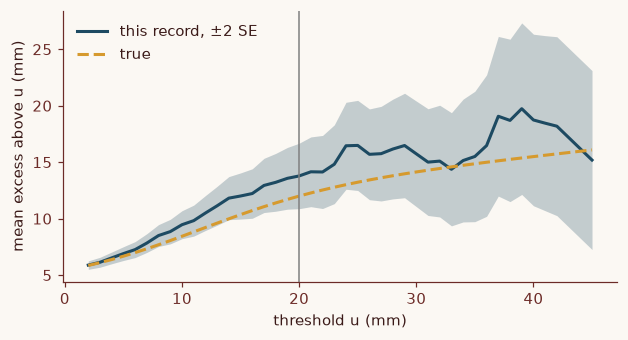

In [5]:
u_grid = np.arange(2, 46, 1.0)
excess = [wet[wet > u] - u for u in u_grid]
me, se = np.array([[e.mean(), e.std(ddof=1) / np.sqrt(e.size)] for e in excess]).T
true_me = ((1 - P_STORM) * MEAN_DRIZZLE * np.exp(-u_grid / MEAN_DRIZZLE) + P_STORM * SIGMA / (1 - XI)
           * (1 + XI * u_grid / SIGMA) * gpd.sf(u_grid, XI, scale=SIGMA)) / wet_sf(u_grid)
fig, ax = plt.subplots(figsize=(6.5, 3.2))
ax.fill_between(u_grid, me - 2 * se, me + 2 * se, color=C1, alpha=0.25, lw=0)
ax.plot(u_grid, me, color=C1, lw=2, label="this record, ±2 SE")
ax.plot(u_grid, true_me, color=C2, lw=2, ls="--", label="true")
ax.axvline(20, color="0.5", lw=1)
ax.set(xlabel="threshold u (mm)", ylabel="mean excess above u (mm)"); ax.legend(frameon=False)
plt.show()

**Figure 2 | Mean-excess plot** of the record's wet days. Band, ±2 standard errors; dashed, the true mean excess; vertical line, the chosen 20 mm.

Above 25 mm the band is so wide that almost any line fits, and the true curve still bends slightly at 20 mm, so refit at a few thresholds and report the spread.

In [6]:
U = 20.0  # threshold read off the mean-excess plot
c, loc, scale = gev.fit(annual_max)
exc = wet[wet > U] - U
xi_p, _, sig_u = gpd.fit(exc, floc=0)
lam = exc.size / 30  # exceedances per year
print(f"GEV on 30 maxima:        xi = {-c:+.3f}, 1-in-100 = {gev.isf(0.01, c, loc, scale):.1f} mm")
print(f"GPD on {exc.size} exceedances: xi = {xi_p:+.3f}, 1-in-100 = {U + sig_u / xi_p * ((lam * 100) ** xi_p - 1):.1f} mm")

GEV on 30 maxima:        xi = +0.223, 1-in-100 = 143.1 mm
GPD on 129 exceedances: xi = +0.179, 1-in-100 = 144.5 mm


The threshold keeps 129 days, $129/30 = 4.3$ a year. Against a true shape of 0.1 the GEV finds 0.223 and the GPD 0.179, and both overshoot the true level by 27 to 29 mm ($143.1 - 115.7$, $144.5 - 115.7$). Overshooting from one 30-year record is common: in the next section 48.1% of 1000 records overshoot ($100\% - 51.9\%$), and this one is higher than 77% of them. Declustering[^3] is skipped because the synthetic days are independent.

## How much a 30-year record can say

A 30-year record places a 1-in-100-year level only within a wide band that leans upward, and even an honest interval misses more often than it claims.

Copy the function below. It fits a GEV and puts a 95% percentile bootstrap interval on the return level by resampling years, as in [Bootstrapping](../bootstrapping/bootstrapping.ipynb).

In [7]:
#| code-fold: false
def return_level(annual_max, T=100, n_boot=1000, seed=0):
    """GEV fit to yearly maxima: return level(s) for period(s) T (years) with a
    95% percentile bootstrap interval (years resampled). Returns level, lo, hi, xi."""
    x, T = np.asarray(annual_max, float), np.asarray(T, float)
    c, loc, scale = gev.fit(x)
    rng = np.random.default_rng(seed)
    boot = [gev.isf(1 / T, *gev.fit(rng.choice(x, x.size), c, loc=loc, scale=scale))
            for _ in range(n_boot)]
    lo, hi = np.percentile(boot, [2.5, 97.5], axis=0)
    return gev.isf(1 / T, c, loc, scale), lo, hi, -c  # xi in the usual sign

1-in-100: 143.1 mm, 95% interval 80.3 to 902.4 mm


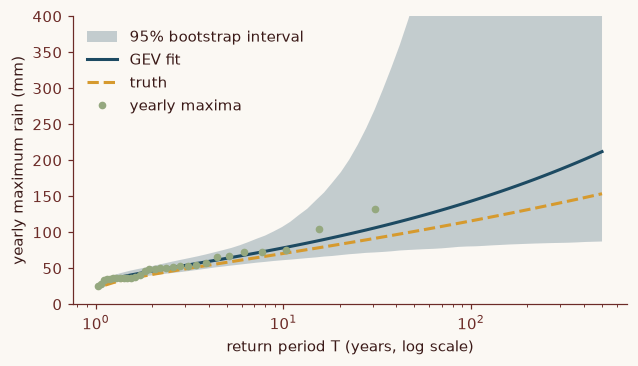

In [8]:
T = np.unique(np.r_[np.logspace(0.05, 2.7, 60), 100])
level, lo, hi, xi_hat = return_level(annual_max, T)
level100, lo100, hi100 = level[T == 100][0], lo[T == 100][0], hi[T == 100][0]
print(f"1-in-100: {level100:.1f} mm, 95% interval {lo100:.1f} to {hi100:.1f} mm")
fig, ax = plt.subplots(figsize=(6.5, 3.4))
ax.fill_between(T, lo, hi, color=C1, alpha=0.25, lw=0, label="95% bootstrap interval")
ax.semilogx(T, level, color=C1, lw=2, label="GEV fit")
ax.semilogx(T, [true_level(t) for t in T], color=C2, lw=2, ls="--", label="truth")
ax.plot((30 + 1) / np.arange(1, 31), np.sort(annual_max)[::-1], "o", color=C4, ms=4, label="yearly maxima")
ax.set(xlabel="return period T (years, log scale)", ylabel="yearly maximum rain (mm)", ylim=(0, 400)); ax.legend(frameon=False)
plt.show()

**Figure 3 | Return-level plot of one synthetic 30-year record.** Dots, yearly maxima at the plotting positions $(n+1)/i$ of [Return periods](../return-periods.qmd); line and band, GEV fit and 95% bootstrap interval, cut at 400 mm; dashed, the truth.

The record gives 143.1 mm with an interval of 80.3 to 902.4 mm. The upper end is not a typo: resamples that repeat the wettest years get a large $\hat\xi$, and the level runs away. Katz and colleagues warn that maximum likelihood can be erratic below about 25 years, especially for extreme quantiles[^3].

How typical is this record? The next cell fits 1000 synthetic records four ways.

In [9]:
rng, rows = np.random.default_rng(7), []
for _ in range(1000):  # 1000 synthetic 100-year records; the first 30 years are the short record
    r = daily_rain(rng, 100)
    am, w30 = r.max(axis=1), r[:30][r[:30] > U] - U
    c30, (xi_p, _, s_u) = gev.fit(am[:30]), gpd.fit(w30, floc=0)
    rows.append([gev.isf(0.01, *c30), stats.gumbel_r.isf(0.01, *stats.gumbel_r.fit(am[:30])),
                 U + s_u / xi_p * ((w30.size / 30 * 100) ** xi_p - 1), gev.isf(0.01, *gev.fit(am)), -c30[0], xi_p])
rows = np.array(rows)
print("1-in-100 level (mm)    median   middle 90%   below truth")
for k, name in enumerate(["GEV, 30 yr", "Gumbel, 30 yr", "GPD over 20 mm, 30 yr", "GEV, 100 yr"]):
    q5, q50, q95 = np.percentile(rows[:, k], [5, 50, 95])
    print(f"{name:22s} {q50:6.1f}   {q5:5.1f}-{q95:5.1f}   {np.mean(rows[:, k] < TRUE100):6.1%}")
print(f"shape below zero: GEV 30 yr {np.mean(rows[:, 4] < 0):.1%}, GPD 30 yr {np.mean(rows[:, 5] < 0):.1%}")
print(f"this notebook's record: {np.mean(rows[:, 0] < level100):.0%} of GEV 30-yr estimates are lower")

1-in-100 level (mm)    median   middle 90%   below truth
GEV, 30 yr              113.6    77.4-207.0    51.9%
Gumbel, 30 yr            98.6    80.8-120.8    90.4%
GPD over 20 mm, 30 yr   119.3    81.7-187.3    44.9%
GEV, 100 yr             117.6    94.5-151.9    45.4%
shape below zero: GEV 30 yr 23.7%, GPD 30 yr 10.1%
this notebook's record: 77% of GEV 30-yr estimates are lower


| Fit | Median (mm) | Middle 90% (mm) | Below truth |
|---|---|---|---|
| GEV, 30 years | 113.6 | 77.4–207.0 | 51.9% |
| Gumbel, 30 years | 98.6 | 80.8–120.8 | 90.4% |
| GPD over 20 mm, 30 years | 119.3 | 81.7–187.3 | 44.9% |
| GEV, 100 years | 117.6 | 94.5–151.9 | 45.4% |

The GEV is centred near the truth, but one record in 20 says more than 207 mm. The Gumbel's narrow band comes from assuming $\xi = 0$, and it is too low in 90.4% of records, as in a worked example of Papalexiou and Koutsoyiannis[^2]. Even 100 years leaves 94.5 to 151.9 mm.

The shape is the weak point: 23.7% of 30-year GEV fits found $\hat\xi < 0$, a ceiling the model does not have (10.1% of threshold fits). Papalexiou and Koutsoyiannis found in 15 137 rainfall records, 40 to 163 years long, that record length strongly affects the fitted shape; extrapolated to very long records, the shapes would be roughly normal with mean 0.114 and standard deviation 0.045[^2]. A positive shape means no daily total is out of reach, only rarer. They argue a ceiling on daily rain is physically inconsistent, but their evidence on the sign is statistical: none of their 16 records longer than 140 years gave a negative shape[^2].

Is the interval honest? The last cell repeats the helper on 200 fresh 30-year records.

In [10]:
rng, hits = np.random.default_rng(8), []
for k in range(200):  # 200 fresh 30-year records, 200 resamples each to keep the run short
    _, lo_k, hi_k, _ = return_level(daily_rain(rng, 30).max(axis=1), 100, n_boot=200, seed=k)
    hits.append(lo_k <= TRUE100 <= hi_k)
print(f"95% intervals containing the truth: {np.mean(hits):.1%} (± {2 * np.std(hits) / np.sqrt(200):.1%})")

95% intervals containing the truth: 90.0% (± 4.2%)


Nominal 95% intervals covered the truth 90.0% of the time (±4.2%), short of their label, as small-sample bootstrap intervals often are.

## When the climate moves: a trend in the location

If the maxima drift upward, a stationary fit averages two climates and is right for neither end. A trending location gives a 1-in-100-year level for each year and a test of the trend.

Katz and colleagues suggest linear trends in location and log scale as a start[^3]; the cell trends the location only, $\mu(t) = \mu_0 + \mu_1 t$ ($t$ in years, $\mu_1$ in mm a year), on 70 synthetic years with a true trend of 0.25 mm a year.

::: {.callout-note collapse="true"}
## How the trend is fitted and tested

Nelder–Mead minimises the negative log-likelihood over $\mu_0$, $\mu_1$, $\ln\sigma$ and $\xi$, starting from the stationary fit. The test is the likelihood ratio $D = 2(\ell_{\text{trend}} - \ell_{\text{stationary}})$, with $\ell$ the maximised log-likelihood, against a chi-square with one degree of freedom.
:::

In [11]:
t = np.arange(70)  # synthetic: GEV with xi = 0.1, scale 11 mm, location 37 mm rising 0.25 mm/yr
am70 = gev.rvs(-0.1, loc=37 + 0.25 * t, scale=11, random_state=np.random.default_rng(11))
nll = lambda th: -gev.logpdf(am70, -th[3], loc=th[0] + th[1] * t, scale=np.exp(th[2])).sum()  # mu0, mu1, log sigma, xi
c0 = gev.fit(am70)
fit = optimize.minimize(nll, [c0[1], 0, np.log(c0[2]), -c0[0]], method="Nelder-Mead",
                        options={"maxiter": 4000, "xatol": 1e-6, "fatol": 1e-8})
mu0, mu1, log_s, xi_t = fit.x
D = 2 * (-gev.logpdf(am70, *c0).sum() - fit.fun)  # likelihood-ratio statistic, 1 extra parameter
print(f"trend {mu1:.2f} mm/yr, xi {xi_t:+.2f}; D = {D:.1f}, p = {stats.chi2.sf(D, 1):.4f}")
for yr in (0, 69):
    print(f"year {yr + 1}: 1-in-100 fitted {gev.isf(0.01, -xi_t, mu0 + mu1 * yr, np.exp(log_s)):.1f} mm, "
          f"true {gev.isf(0.01, -0.1, 37 + 0.25 * yr, 11):.1f} mm")
print(f"stationary fit to all 70 years: {gev.isf(0.01, *c0):.1f} mm")

trend 0.19 mm/yr, xi +0.25; D = 13.4, p = 0.0002
year 1: 1-in-100 fitted 116.9 mm, true 101.3 mm
year 70: 1-in-100 fitted 130.3 mm, true 118.5 mm
stationary fit to all 70 years: 108.5 mm


The trend is detected ($p = 0.0002$) at 0.19 mm a year. The fitted 1-in-100 level rises 13.4 mm over the record ($130.3 - 116.9$), the true one 17.2 mm; the stationary 108.5 mm is too high at the start and too low at the end. Both fitted levels sit 12 to 16 mm above the truth because $\hat\xi$ is 0.25, not 0.10: the trend is easier to estimate than the tail. For intervals, resample residuals transformed to a standard form, not raw years[^3]. [Heatwaves in a warming climate](../heatwaves-in-a-warming-climate.qmd) describes an attribution study that fitted this kind of model.

## Key takeaways

My own practice rules, from the synthetic runs above rather than tests on real records:

- **Check the sign, then plot before you quote.** In `scipy.stats.genextreme` a heavy tail has negative `c`; show return levels with data and interval.
- **Distrust a short record's shape.** A negative $\hat\xi$ from 30 years of rain is more likely noise than a ceiling; anchor on a regional shape from long records[^2] and check it against $1/\alpha$ from the daily data.
- **For daily data, prefer peaks over threshold**, declustered, at three thresholds; do not fall back on the Gumbel for a tidier interval.
- **Read a 95% bootstrap interval from 30 maxima as nearer 90%**, and under a trend quote the level for the year the drain, planting or contract must survive.

## References

[^1]: Fisher, R. A. & Tippett, L. H. C. Limiting forms of the frequency distribution of the largest or smallest member of a sample. *Math. Proc. Camb. Philos. Soc.* **24**, 180–190 (1928). https://doi.org/10.1017/S0305004100015681
[^2]: Papalexiou, S. M. & Koutsoyiannis, D. Battle of extreme value distributions: a global survey on extreme daily rainfall. *Water Resour. Res.* **49**, 187–201 (2013). https://doi.org/10.1029/2012WR012557
[^3]: Katz, R. W., Parlange, M. B. & Naveau, P. Statistics of extremes in hydrology. *Adv. Water Resour.* **25**, 1287–1304 (2002). https://doi.org/10.1016/S0309-1708(02)00056-8
[^4]: Davison, A. C. & Smith, R. L. Models for exceedances over high thresholds. *J. R. Stat. Soc. B* **52**, 393–425 (1990). https://doi.org/10.1111/j.2517-6161.1990.tb01796.x

<!-- CURRICULUM_FOOTER_START -->
<div class="mf"><a class="mf-prev" href="/blogs/return-periods.html"><span>Previous</span>Return periods</a><a class="mf-up" href="/series/prediction/index.html"><span>Series</span>Weather, Climate and Prediction</a><a class="mf-next" href="/blogs/heatwaves-in-a-warming-climate.html"><span>Next</span>Heatwaves in a warming climate</a></div>
<!-- CURRICULUM_FOOTER_END -->